PASO 0: INVOCACIÓN DE LIBRERÍAS

In [177]:
# Apertura de librerías
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import math
from scipy import stats

# PASO 1: APERTURA DEL ARCHIVO DE DATOS Y ESTUDIO PRELIMINAR

In [178]:
games = pd.read_csv('/datasets/games.csv')

# PASO 2: PREPARACIÓN DE DATOS

In [179]:
# 2.0 Revisión general de los datos
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [180]:
#2.1 Transformación de nombres a puras minúsculas
new_col_names = []

for old_name in games.columns:
    name_lowered = old_name.lower()
    new_col_names.append(name_lowered)

games.columns = new_col_names

In [181]:
print(games.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')


In [182]:
#2.2 Conversiones de tipos de datos

#2.2.1 Generación de una columna de id por si fuera necesario cruzar este df después con algún otro
print(games.index)

games.reset_index(inplace=True)
games.rename(columns={'index': 'id_game'}, inplace=True)
games.info()

RangeIndex(start=0, stop=16715, step=1)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_game          16715 non-null  int64  
 1   name             16713 non-null  object 
 2   platform         16715 non-null  object 
 3   year_of_release  16446 non-null  float64
 4   genre            16713 non-null  object 
 5   na_sales         16715 non-null  float64
 6   eu_sales         16715 non-null  float64
 7   jp_sales         16715 non-null  float64
 8   other_sales      16715 non-null  float64
 9   critic_score     8137 non-null   float64
 10  user_score       10014 non-null  object 
 11  rating           9949 non-null   object 
dtypes: float64(6), int64(1), object(5)
memory usage: 1.5+ MB


In [183]:
# Revisión de los primeros 20 niveles y luego una muestra
print("Primeros veinte registros:")
print(games.head(20))
print()
print("Muestra de veinte registros:")
print(games.sample(20))

Primeros veinte registros:
    id_game                                          name platform  \
0         0                                    Wii Sports      Wii   
1         1                             Super Mario Bros.      NES   
2         2                                Mario Kart Wii      Wii   
3         3                             Wii Sports Resort      Wii   
4         4                      Pokemon Red/Pokemon Blue       GB   
5         5                                        Tetris       GB   
6         6                         New Super Mario Bros.       DS   
7         7                                      Wii Play      Wii   
8         8                     New Super Mario Bros. Wii      Wii   
9         9                                     Duck Hunt      NES   
10       10                                    Nintendogs       DS   
11       11                                 Mario Kart DS       DS   
12       12                   Pokemon Gold/Pokemon Silver      

In [184]:
#2.2.2 Conversiones categóricas (platform, genre, rating)
games = games.astype({
    'platform': 'category',
    'genre': 'category',
    'rating': 'category'
})
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   id_game          16715 non-null  int64   
 1   name             16713 non-null  object  
 2   platform         16715 non-null  category
 3   year_of_release  16446 non-null  float64 
 4   genre            16713 non-null  category
 5   na_sales         16715 non-null  float64 
 6   eu_sales         16715 non-null  float64 
 7   jp_sales         16715 non-null  float64 
 8   other_sales      16715 non-null  float64 
 9   critic_score     8137 non-null   float64 
 10  user_score       10014 non-null  object  
 11  rating           9949 non-null   category
dtypes: category(3), float64(6), int64(1), object(2)
memory usage: 1.2+ MB


In [185]:
#2.2.3 Conversiones numéricas (user_score). 
games['user_score'] = games['user_score'].replace('tbd', np.nan).astype(float)
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   id_game          16715 non-null  int64   
 1   name             16713 non-null  object  
 2   platform         16715 non-null  category
 3   year_of_release  16446 non-null  float64 
 4   genre            16713 non-null  category
 5   na_sales         16715 non-null  float64 
 6   eu_sales         16715 non-null  float64 
 7   jp_sales         16715 non-null  float64 
 8   other_sales      16715 non-null  float64 
 9   critic_score     8137 non-null   float64 
 10  user_score       7590 non-null   float64 
 11  rating           9949 non-null   category
dtypes: category(3), float64(7), int64(1), object(1)
memory usage: 1.2+ MB


In [186]:
#2.3 Cálculo de ventas totales (suma de las ventas en todas las regiones) para cada juego

games['total_sales'] = games['na_sales'] + games['eu_sales'] + games['jp_sales'] + games['other_sales']
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   id_game          16715 non-null  int64   
 1   name             16713 non-null  object  
 2   platform         16715 non-null  category
 3   year_of_release  16446 non-null  float64 
 4   genre            16713 non-null  category
 5   na_sales         16715 non-null  float64 
 6   eu_sales         16715 non-null  float64 
 7   jp_sales         16715 non-null  float64 
 8   other_sales      16715 non-null  float64 
 9   critic_score     8137 non-null   float64 
 10  user_score       7590 non-null   float64 
 11  rating           9949 non-null   category
 12  total_sales      16715 non-null  float64 
dtypes: category(3), float64(8), int64(1), object(1)
memory usage: 1.3+ MB


In [187]:
# Corrección de un dato que genera problemas al momento de gráficar y que es un error
error_1985 = games[games['year_of_release'] == 1985]
print(error_1985[error_1985['platform'] == 'DS'])
games.loc[15957, 'year_of_release'] = 2007
print(games.loc[15957])

       id_game                                 name platform  year_of_release  \
15957    15957  Strongest Tokyo University Shogi DS       DS           1985.0   

        genre  na_sales  eu_sales  jp_sales  other_sales  critic_score  \
15957  Action       0.0       0.0      0.02          0.0           NaN   

       user_score rating  total_sales  
15957         NaN    NaN         0.02  
id_game                                          15957
name               Strongest Tokyo University Shogi DS
platform                                            DS
year_of_release                                 2007.0
genre                                           Action
na_sales                                           0.0
eu_sales                                           0.0
jp_sales                                          0.02
other_sales                                        0.0
critic_score                                       NaN
user_score                                         NaN
rat

In [188]:
# 2.4 Trato de los valores ausentes
print(games[games['name'].isna()])

       id_game name platform  year_of_release genre  na_sales  eu_sales  \
659        659  NaN      GEN           1993.0   NaN      1.78      0.53   
14244    14244  NaN      GEN           1993.0   NaN      0.00      0.00   

       jp_sales  other_sales  critic_score  user_score rating  total_sales  
659        0.00         0.08           NaN         NaN    NaN         2.39  
14244      0.03         0.00           NaN         NaN    NaN         0.03  


# DOCUMENTACIÓN 
1. Se reseteó el index y se conservó la columna anterior para tener una columna de id (id_game) que permita conectar el df con otros, de ser necesario.
2. Se cambió platform, genre, rating a tipo category. Esto reducirá los usos de memoria y permitirá búsquedas más eficientes con estos campos que tradicionalmente tienen un bajo grado de cardinalidad.
3. Se sustituyó el valor tbd por np.nan en el campo "user_score". Esto permite mantener la idea original ("Aún no sabemos el valor de este registro"), pero con un tipo de dato que es amigable con el cálculo numérico de toda la columna. Se decidió no rellenarlo con algún valor para no inventar calificaciones ni generar una falsa tendencia hacia la peor calificación posible (cero). 
4. Se calcularon las ventas totales de cada juego y se colocó el resultado en una nueva columna llamada total_sales.
5. Los campos que tienen más valores ausentes son las calificaciones, tanto de críticos como de usuarios, y rating. Asumo que se debe a que esas calificaciones no se tienen todavía. Decidí dejarlo como nulos porque cambiarlos a otro valor más procesable podría generar confusiones (por ejemplo, 0 podría interpretarse como una muy mala calificación). Hay dos juegos de Genesis que no se tiene el nombre. 

# 3. ANÁLISIS DE DATOS

In [189]:
# Se define un período relevante de análisis, dado que el objetivo es planear la campaña de 2017
# Se propone un rango de los últimos ~5-7 años (2010-2016) dado el ciclo promedio de vida encontrado (10.16 años)
games_recent = games[games["year_of_release"] >= 2010].copy()

# Bucle para eliminar las categorías que no se usan en el nuevo games_recent
categorical_columns = ['platform', 'genre', 'rating']
for col in categorical_columns:
    games_recent[col] = games_recent[col].cat.remove_unused_categories()


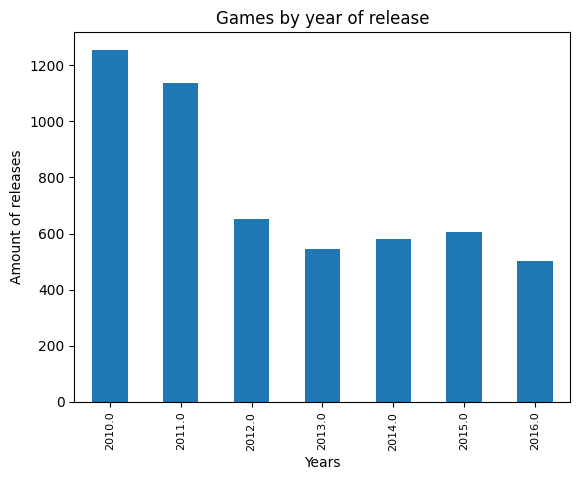

In [190]:
# 3.1 Cantidad de juegos que fueron lanzados en diferentes años. 

games_by_release = games_recent.groupby('year_of_release')['id_game'].count()

games_by_release.plot(
    kind='bar',
    title='Games by year of release',
    legend=False,
    xlabel='Years',
    ylabel='Amount of releases'
)
plt.tick_params(axis='x', labelsize=8)
plt.show()

   platform  total_sales
0       PS2         6.09
1       PSV        53.81
2       PSP        64.05
3      WiiU        82.19
4        PC       121.96
5        DS       123.75
6      XOne       159.32
7       Wii       222.97
8       3DS       257.81
9       PS4       314.14
10     X360       550.41
11      PS3       587.74


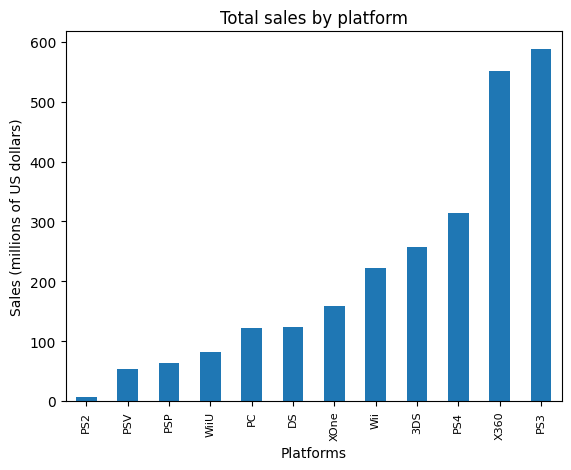

In [191]:
# 3.2 Variación de las ventas por plataforma

total_sales_by_platform = games_recent.groupby(['platform'])['total_sales'].sum().sort_values().reset_index()
print(total_sales_by_platform)

total_sales_by_platform.plot(
     kind='bar',
     title='Total sales by platform',
     legend=False,
     xlabel='Platforms',
     ylabel='Sales (millions of US dollars)',
    x='platform'

 )
plt.tick_params(axis='x', labelsize=8)
plt.show()


In [192]:
# 3.3 Distribución de las ventas basada en los datos de cada año

biggest_platforms = ['XOne', 'Wii', '3DS', 'PS4', 'X360', 'PS3']
# Se genera una consulta de la df, se guarda en otra variable y se garantiza que el resultado sea una copia nueva y no una 
# mera "vista" de la df original con el método .copy()
games_biggest_platforms = games_recent[games_recent['platform'].isin(biggest_platforms)].copy()
# Se quitan las categorías que no se están usando para que el filtrado funcione. Interesante función de category.
# Python recuerda las categorías aunque se hayan eliminado. 
games_biggest_platforms['platform'] = games_biggest_platforms['platform'].cat.remove_unused_categories()

print(games_biggest_platforms['platform'].unique())

sales_by_platform_year = games_biggest_platforms.groupby(['platform', 'year_of_release'])['total_sales'].sum().sort_values(ascending=True).reset_index()


['X360', 'PS3', 'PS4', '3DS', 'Wii', 'XOne']
Categories (6, object): ['X360', 'PS3', 'PS4', '3DS', 'Wii', 'XOne']


platform           3DS     PS3     PS4     Wii    X360   XOne
year_of_release                                              
2010.0            0.00  142.17    0.00  127.95  170.03   0.00
2011.0           63.20  156.78    0.00   59.65  143.84   0.00
2012.0           51.36  107.36    0.00   21.71   99.74   0.00
2013.0           56.57  113.25   25.99    8.59   88.58  18.96
2014.0           43.76   47.76  100.00    3.75   34.74  54.07
2015.0           27.78   16.82  118.90    1.14   11.96  60.14
2016.0           15.14    3.60   69.25    0.18    1.52  26.15


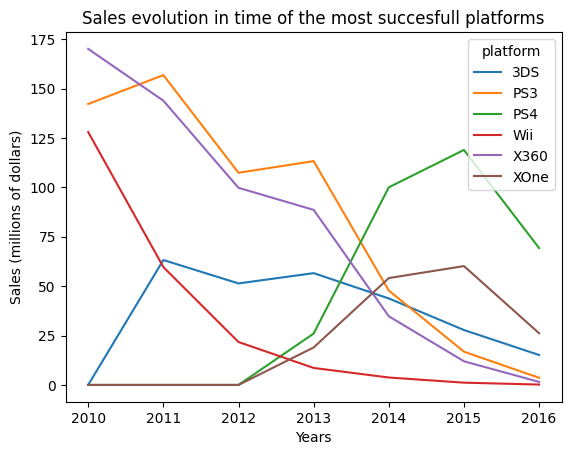

In [193]:
# Se reordena la información con una tabla dinámica para poder trazar en una gráfica cada plataforma por separado

pivot_data = sales_by_platform_year.pivot_table(
    index = 'year_of_release',
    columns = 'platform',
    values = 'total_sales',
    aggfunc= 'sum'
)



print(pivot_data.head(10))



pivot_data.plot(
    xlabel='Years',
    ylabel='Sales (millions of dollars)',
    title='Sales evolution in time of the most succesfull platforms'
)


plt.show()



In [194]:
print(f"El año de más ventas de XOne fue: {pivot_data['XOne'].idxmax()} con ventas de {pivot_data['XOne'].max()} millones de dólares")
print(f"El año de más ventas de XOne fue: {pivot_data['3DS'].idxmax()} con ventas de {pivot_data['3DS'].max()} millones de dólares")
print(f"El año de más ventas de PS2 fue: {pivot_data['PS4'].idxmax()} con ventas de {pivot_data['PS4'].max()} millones de dólares")
print(f"El año de más ventas de Wii fue: {pivot_data['Wii'].idxmax()} con ventas de {pivot_data['Wii'].max()} millones de dólares")
print(f"El año de más ventas de X360 fue: {pivot_data['X360'].idxmax()} con ventas de {pivot_data['X360'].max()} millones de dólares")
print(f"El año de más ventas de PS3 fue: {pivot_data['PS3'].idxmax()} con ventas de {pivot_data['PS3'].max()} millones de dólares")

El año de más ventas de XOne fue: 2015.0 con ventas de 60.14000000000002 millones de dólares
El año de más ventas de XOne fue: 2011.0 con ventas de 63.2 millones de dólares
El año de más ventas de PS2 fue: 2015.0 con ventas de 118.90000000000008 millones de dólares
El año de más ventas de Wii fue: 2010.0 con ventas de 127.95 millones de dólares
El año de más ventas de X360 fue: 2010.0 con ventas de 170.02999999999992 millones de dólares
El año de más ventas de PS3 fue: 2011.0 con ventas de 156.7800000000001 millones de dólares


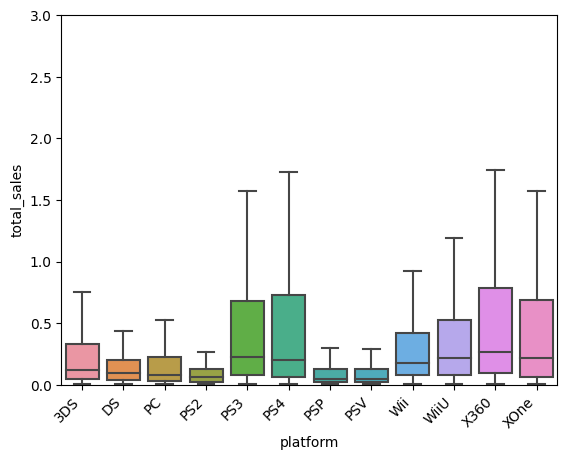

In [195]:
# 3.4 Diagrama de caja para las ventas globales de todos los juegos desglosados por plataforma
sns.boxplot(
    data=games_recent,
    x='platform',
    y='total_sales',
    showfliers=False
)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 3)
plt.show()


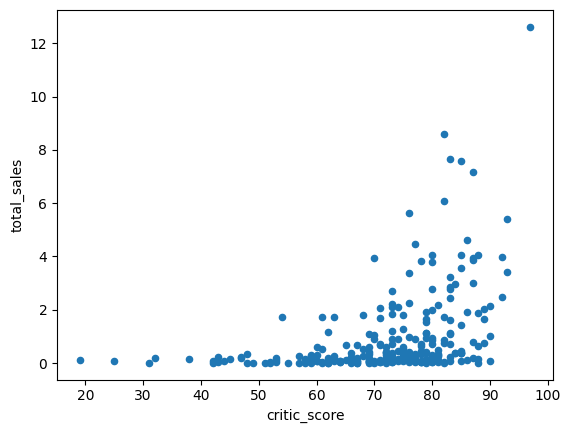

Correlación críticos: 0.40656790206178095


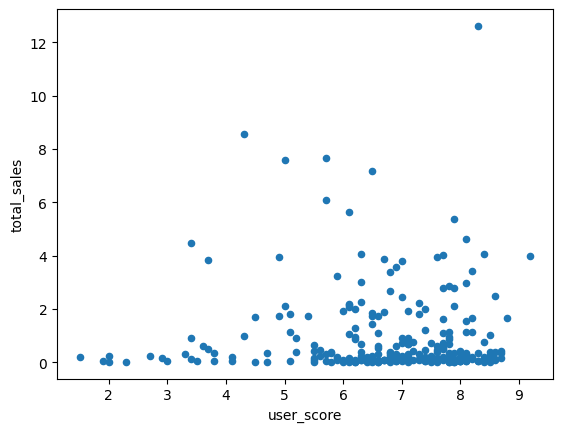

Correlación usuarios: -0.031957110204556376
Correlación entre calificaciones de críticos y ventas totales: 0.40656790206178095

Correlación entre calificaciones de usuarios y ventas totales: -0.031957110204556376


In [196]:
# 3.5 Gráfico de dispersión para reseñas y ventas, y cálculo de correlación
ps4 = games_recent[games_recent["platform"] == "PS4"]

ps4_critic = ps4.dropna(subset=["critic_score", "total_sales"])
ps4_user   = ps4.dropna(subset=["user_score", "total_sales"])

ps4_critic.plot(kind="scatter", x="critic_score", y="total_sales")
plt.show()
print("Correlación críticos:", ps4_critic["critic_score"].corr(ps4_critic["total_sales"]))

ps4_user.plot(kind="scatter", x="user_score", y="total_sales")
plt.show()
print("Correlación usuarios:", ps4_user["user_score"].corr(ps4_user["total_sales"]))


print(f"Correlación entre calificaciones de críticos y ventas totales: {ps4_critic['critic_score'].corr(ps4_critic['total_sales'])}")
print()
print(f"Correlación entre calificaciones de usuarios y ventas totales: {ps4_user['user_score'].corr(ps4_user['total_sales'])}")


In [197]:
#3.6 Comparación de las ventas de los mismos juegos en otras plataformas
# Obtención de los juegos que aparecen en más de una plataforma
games_in_many_platforms = games_recent.groupby('name')['platform'].nunique().sort_values(ascending=False).reset_index()
games_in_many_platforms.rename(columns={'platform': 'platform_count'}, inplace=True)
print(games_in_many_platforms.head(15))
print()
games_in_many_platforms = games_in_many_platforms[games_in_many_platforms['platform_count'] > 1]
print(games_in_many_platforms.head(15))

# Query de games para quedarnos sólo con los datos de los juegos que aparecen en más de una plataforma
full_data_multiplatform_games = games_recent[games_recent['name'].isin(games_in_many_platforms['name'])]
print(full_data_multiplatform_games.head(15))
full_data_multiplatform_games = full_data_multiplatform_games.sort_values(by='total_sales', ascending=False)
print(full_data_multiplatform_games.head(15))

                                             name  platform_count
0                        LEGO Marvel Super Heroes               9
1                                         FIFA 14               9
2                             LEGO Jurassic World               8
3                    Lego Batman 3: Beyond Gotham               8
4                        The LEGO Movie Videogame               8
5                                 LEGO The Hobbit               8
6                                         FIFA 15               8
7                                        Terraria               8
8                                  FIFA Soccer 13               8
9                           Angry Birds Star Wars               8
10              Lego Star Wars: The Force Awakens               7
11                      Pro Evolution Soccer 2012               7
12                     LEGO The Lord of the Rings               7
13                          Skylanders SWAP Force               7
14  LEGO P

In [198]:
# Agrupación adicional de todos los juegos multiplataforma para tener la lista de juegos con mayores ventas totales

total_sales_multiplatform_games = full_data_multiplatform_games.groupby('name')['total_sales'].sum().sort_values(ascending=False).reset_index()


print(total_sales_multiplatform_games.head(10))


                             name  total_sales
0              Grand Theft Auto V        56.58
1  Call of Duty: Modern Warfare 3        30.60
2      Call of Duty: Black Ops II        29.40
3         Call of Duty: Black Ops        29.20
4            Call of Duty: Ghosts        27.39
5       Call of Duty: Black Ops 3        25.67
6                       Minecraft        24.16
7  Call of Duty: Advanced Warfare        21.97
8     The Elder Scrolls V: Skyrim        21.14
9                         FIFA 15        17.37


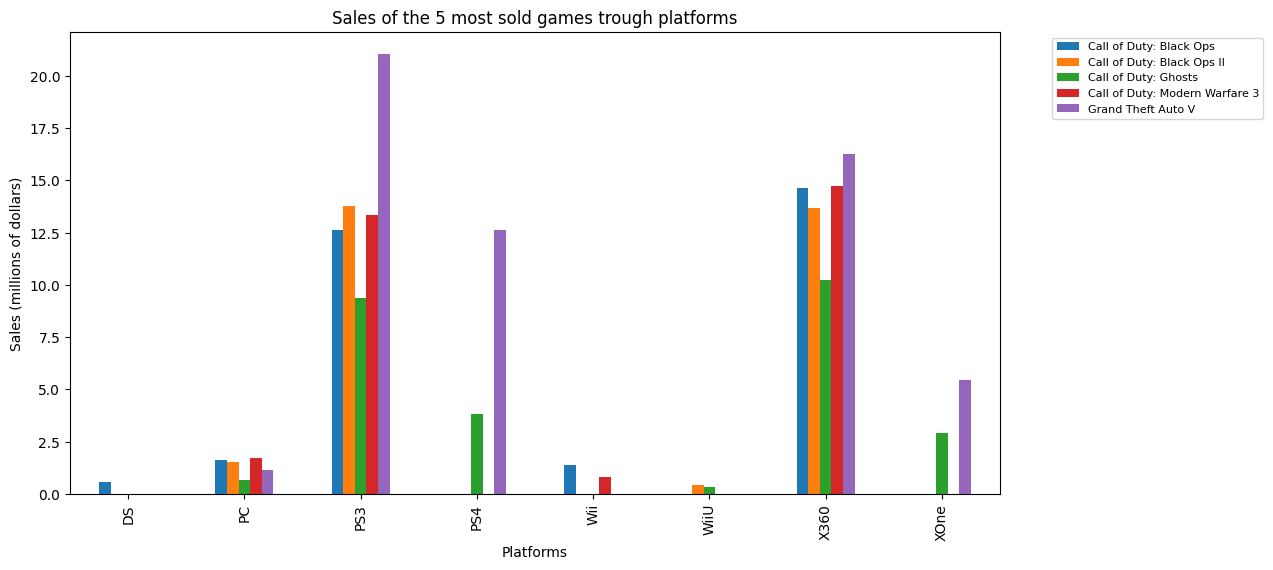

In [199]:
# Uso de la lista para obtener la información de ventas por plataforma de los juegos más vendidos () y sacar conclusiones

most_sold_multiplatform_games_total = total_sales_multiplatform_games.head(5)
most_sold_multiplatform_games = most_sold_multiplatform_games_total['name']
most_sold_mp_games_full_data = games[games['name'].isin(most_sold_multiplatform_games)].copy()
most_sold_mp_games_full_data['platform'] = most_sold_mp_games_full_data['platform'].cat.remove_unused_categories()

pivot_data = most_sold_mp_games_full_data.pivot_table(
    index = 'platform',
    columns = 'name',
    values = 'total_sales',
    aggfunc= 'sum'
)
pivot_data = pivot_data.dropna(how='all')

pivot_data.plot(
    xlabel='Platforms',
    ylabel='Sales (millions of dollars)',
    title='Sales of the 5 most sold games trough platforms',
    kind='bar',
    figsize=(12, 6)
)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.show()


           genre  total_sales
0         Action       673.09
1        Shooter       479.74
2         Sports       328.39
3   Role-Playing       315.28
4           Misc       234.56
5         Racing       122.68
6       Platform       119.72
7       Fighting        81.59
8     Simulation        71.75
9      Adventure        61.00
10      Strategy        35.84
11        Puzzle        20.60


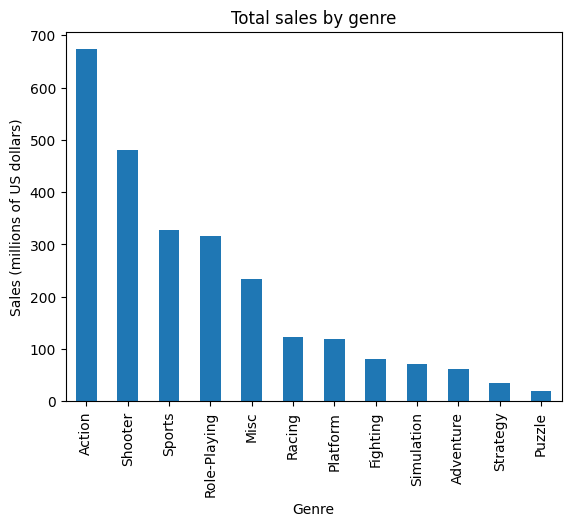

In [200]:
# 3.7 Análisis de la distribución general de los juegos por género.
games_by_genre = games_recent.groupby('genre')['total_sales'].sum().sort_values(ascending=False).reset_index()
print(games_by_genre.head(20))

games_by_genre.plot(
     kind='bar',
     title='Total sales by genre',
     legend=False,
     xlabel='Genre',
     ylabel='Sales (millions of US dollars)',
    x='genre',
    y='total_sales'
)
plt.show()

# CONCLUSIONES DEL PASO 3
1. Es posible distinguir cuando menos tres periodos importantes en cuanto a lanzamientos. Los primeros años (1980 a 1990) se caracterizaron por pocos lanzamientos en cantidades muy parecidas año con año. Luego, hay una clara tendencia a la alta a partir de 1991 que se sostiene hasta 2009; año que junto con 2008 comparte la mayor cantidad de lanzamientos de 1980 a la fecha. Finalmente, la tercera época corre de 2012 a 2016; caracterizado por una disminución de ventas con respecto a los picos de 2008 y 2009 y una establización en los años que ronda entre 400 y 600 lanzamientos en todos esos años. Hay un pequeño periodo intermedio (2010-2011); estos dos años se caracterizaron por ser disminuciones frente al pico de 2009 hasta llegar al rango estabilizado de lanzamientos (400-600) que empieza en 2011.
2. La variación de ventas totales por plataforma es significativa: mientras PCFX, GG, 3DO, TG16, WS, NG y SCD no llegan ni al millón de dólares estadounidenses en sus ventas totales, PS2 llegó a 1255.77 millones de dólares estadounidenses (es la de mayores ventas de la tabla).
3. Antes de proseguir, se aplicó un criterio de relevancia: no queremos trabajar con todas las plataformas de todos los años, sino con las plataformas más relevantes para la planeación de la campaña de 2017. Para ello, se buscó un ciclo de vida promedio para las consolas.
4. La gráfica de distribución de ventas en el tiempo de las plataformas más vendidas muestra lo siguiente: PS fue el primer gran éxito. Duró aproximadamente de 1995 a 2003 (8 años). Su culminación fue 1998 con ventas por 169.49 millones de dólares. Luego vino PS2; la plataforma más exitosa de todas. Su dominio duró de 1998 aproximadamente a 2010 (12 años). Su mejor año fue 2004 con ventas de 211.8099 millones de dólares. A continuación vino la DS, que empezó como por el 2004 y duró como hasta el 2013 (9 años) y tuvo su mejor año en 2007 con 146.94 millones de dólares. Luego la Wii, que empezó en 2005 y culminó como en 2015 (10 años), y tuvo su mejor año en 2009 con ventas de 206.97 millones de dólares. Luego, la X360 que también empezó en 2005 pero se extendió un año más en 2016 (11 años) y tuvo su mejor año en 2010 con 170.0299 millones de dólares y, finalmente, la PS3 que tuvo el mismo rango de acción (2005-2016, 11 años) y tuvo su mejor año en 2011 con ventas de 156.78 millones de dólares.
5. El promedio de vigencia de estas consolas (tiempo de aparición hasta el momento en el que ya no venden) es de 10.16667 años.
6. Se corrigieron algunos datos. Por ejemplo: la base dice que el primer juego de DS salió en 1985. Esto es un error. Se trata de Strongest Tokyo University Shogi que, para DS, salió en 2007.
7. El promedio de 10.16 años justifica definir el periodo reciente de 2010 a la fecha. Se tomó este rango para los análisis posteriores. 
8. De igual forma, queda resuelta la pregunta sobre las plataformas líderes en ventas, cuáles crecen y cuáles se reducen. Estas últimas dos preguntas en realidad deben venir acompañadas de una variable adicional: ¿cuándo? Porque todas crecen y todas se reducen dependiendo del tiempo, tal y como se ve en la gráfica de distribución.
9. Hay un dato adicional muy importante tomado del análisis de la evolución de las ventas en el tiempo de las plataformas más exitosas de 2010 a la fecha. Esa gráfica muestra con claridad que, de todas las plataformas relevantes, sólo XOne y PS4 tienen una tendencia en ventas que las califica como plataformas "vivas". Por tanto, aunque algunas otras plataformas puedan llegar a tener números absolutos más importantes (como X360, que fue un exitazo en ventas), la tendencia obliga a considerar siempre a XOne y PS4 como nuestras principales consolas referencia y a descartar a grandes éxitos como X360 como referencias principales para la planeación de 2017, dada su "muerte", o tendencia claramente en declive en ventas.
10. En cuanto a la gráfica de cajas, de todas las plataformas relevantes de 2010 a la fecha es notoria la amplitud de la caja de PS4, PS3, X360 y XOne. Además, tienen valores máximos relativamente elevados, comparados con las demás plataformas. A pesar de estas diferencias, las medianas de estas plataformas son muy parecidas. 
11. En cuanto a la relación entre calificaciones y ventas totales (en las que se tomó a PS4 como referencia) nos encontramos con una relación positiva débil para el caso de las calificaciones de los críticos y negativa muy débil para el caso de usuarios. La correlación entre calificaciones de críticos y ventas totales es de 0.40656790206178095; mientras que la correlación entre calificaciones de usuarios y ventas totales es de -0.031957110204556376. Sin embargo, aunque no hay una relación lineal fuerte y clara entre calificación y ventas, sí existe una tendencia leve: en PS4, los juegos con ventas muy altas tienden a concentrarse más en el rango de calificaciones de 6 a 10, en lugar de estar distribuidos uniformemente en todo el rango (incluyendo calificaciones bajas de 0 a 5). Esto sugiere que una calificación baja parece limitar las posibilidades de tener ventas muy altas (pocos juegos mal calificados venden muchísimo), pero una calificación alta no garantiza ventas altas (hay juegos bien calificados que venden poco). Es decir, la buena calificación podría ser más una condición "necesaria pero no suficiente" para el éxito comercial masivo, y no una causa directa.
12. Para el caso de la relación entre calificaciones de usuarios y ventas, dada la gran debilidad de la correlación es más difícil establecer alguna relación relevante. Sin embargo, parece generarse una condición parecida de necesaria pero no suficiente para altas ventas, a partir más o menos de poco más de calificación de 3. 
13. Para el análisis de las ventas de los mismos juegos en otras plataformas se obtuvieron primero los juegos multiplataforma con la mayor cantidad de ventas totales. Luego, se tomaron los 5 juegos más vendidos y se usó una gráfica de barras para observar su comportamiento en cada una de las plataformas en las que tienen participación. La franquicia de Call of Duty establece una clara dominación para el caso multiplataforma: 4 de los 5 juegos multiplataforma más vendidos pertenecen a esa franquicia (Black Ops, Black Ops II, Ghosts y Modern Warfare 3). Sin embargo, el multiplataforma más vendido de la época reciente es Grand Theft Auto V.
14. XOne y PS4 son las plataformas más relevantes para evaluar las ventas de juegos multiplataforma por su condición de plataformas "vivas". Ahí, Gran Theft Auto muestra dominio en ambas, y Ghosts muestra presencia importante. Los demás juegos muestran tendencias más o menos interesantes entre plataformas. Un caso interesante es la menor participación de Gran Theft Auto V en PC. En esta plataforma, en general, los Call of Duty han tenido un mejor desempeño. 
15. El género con más ingresos es acción (673.09 de dólares) seguido de shooters (479.74 millones de dólares). El de menos ingreso es rompecabezas (menos de 20.60 millones de dólares), y el segundo con menos ingreso es estrategia (con 35.84 millones de dólares). Para saber la rentabilidad tendríamos que saber el costo de cada juego y sacar un promedio de rentabilidad. Este dato no está disponible. Pero por ventas, parece que lo mejor es hacer juegos de acción y balazos. Es posible percibir cuatro grandes secciones de ingreso: el primero lo ocupa únicamente acción, pues la diferencia con el segundo lugar, shooters, es considerable. La segunda es shooters porque también tiene una diferencia considerable con el tercer lugar, deportes. La tercera sección va de deportes a misc, y la cuarta sería de "ingreso bajo" y va de carreras hasta rompecabezas.  

# Paso 4: Perfil de usuario para cada región

  platform  na_sales  jp_sales  eu_sales
0      3DS     82.65    100.62     61.27
1       DS     59.66     27.90     28.06
2       PC     39.07      0.00     68.82
3      PS2      2.32      0.80      1.67
4      PS3    229.25     59.26    213.60
5      PS4    108.74     15.96    141.09
6      PSP      9.65     42.20      7.59
7      PSV     12.47     21.84     13.07
8      Wii    121.20     17.75     65.91
9     WiiU     38.10     13.01     25.13


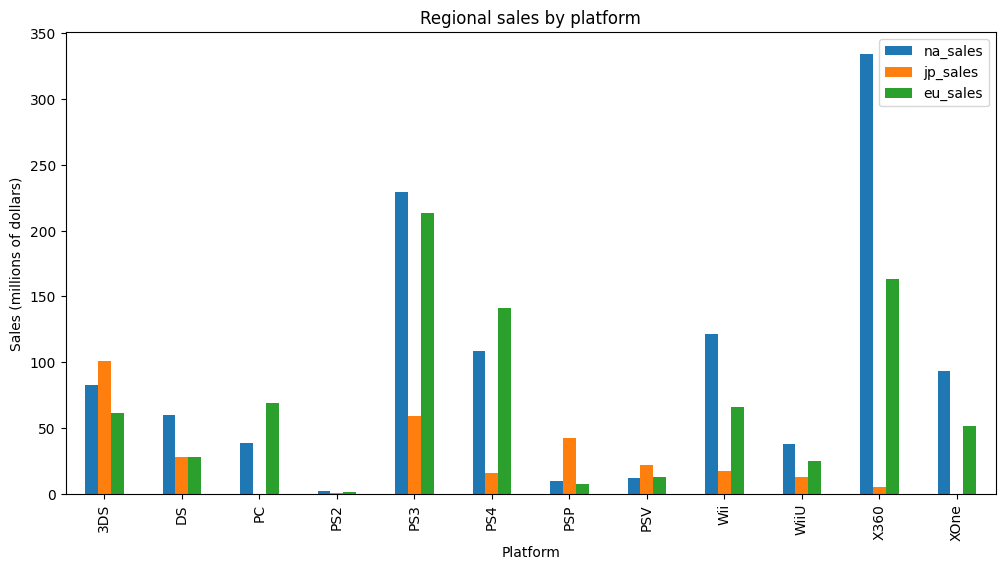

In [201]:
# 4.1 Análisis inicial de todas las plataformas por región para describir variaciones en cuotas de mercado de una región a otra
regional_sales_by_platform = games_recent.groupby('platform')[['na_sales', 'jp_sales', 'eu_sales']].sum().reset_index()
print(regional_sales_by_platform.head(10))
regional_sales_by_platform.plot(

    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Regional sales by platform',
    x='platform',
    figsize=(12,6)

)
plt.show()

   platform  na_sales  jp_sales  eu_sales
10     X360    334.18      5.46    163.41
4       PS3    229.25     59.26    213.60
8       Wii    121.20     17.75     65.91
5       PS4    108.74     15.96    141.09
11     XOne     93.12      0.34     51.59
   platform  na_sales
10     X360    334.18
4       PS3    229.25
8       Wii    121.20
5       PS4    108.74
11     XOne     93.12


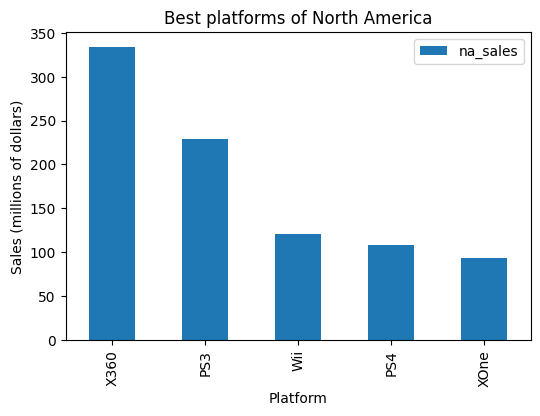

El promedio de ventas para las 5 mejoras plataformas de Norteamérica es: 177.29800000000006 millones de dólares


In [202]:
# 4.2 Determinación de las 5 plataformas principales por región para su describir las variaciones de mercado.
# 4.2.1 Determinación de Norteamérica
biggest_sales_na_platform = regional_sales_by_platform.sort_values(by='na_sales', ascending=False)
print(biggest_sales_na_platform.head(5))
list_na_platform = biggest_sales_na_platform['platform'].head(5)
biggest_sales_na_platform = biggest_sales_na_platform[biggest_sales_na_platform['platform'].isin(list_na_platform)]
biggest_sales_na_platform = biggest_sales_na_platform.drop(columns=['jp_sales', 'eu_sales'])
print(biggest_sales_na_platform)

biggest_sales_na_platform.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best platforms of North America',
    x='platform',
    figsize=(6,4)
)
plt.show()
mean_best_na_platforms = biggest_sales_na_platform['na_sales'].mean()
print(f"El promedio de ventas para las 5 mejoras plataformas de Norteamérica es: {mean_best_na_platforms} millones de dólares")

   platform  na_sales  jp_sales  eu_sales
4       PS3    229.25     59.26    213.60
10     X360    334.18      5.46    163.41
5       PS4    108.74     15.96    141.09
2        PC     39.07      0.00     68.82
8       Wii    121.20     17.75     65.91
   platform  eu_sales
4       PS3    213.60
10     X360    163.41
5       PS4    141.09
2        PC     68.82
8       Wii     65.91


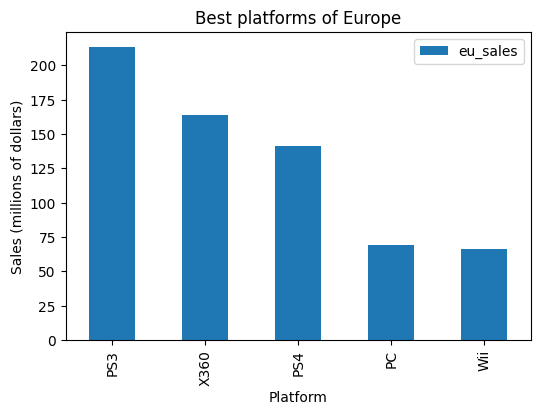

El promedio de ventas para las 5 mejoras plataformas de Europa es: 130.56600000000043 millones de dólares


In [203]:

# 4.2.1 Determinación de Europa
biggest_sales_eu = regional_sales_by_platform.sort_values(by='eu_sales', ascending=False)
print(biggest_sales_eu.head(5))
list_eu = biggest_sales_eu['platform'].head(5)
biggest_sales_eu = biggest_sales_eu[biggest_sales_eu['platform'].isin(list_eu)]
biggest_sales_eu = biggest_sales_eu.drop(columns=['na_sales', 'jp_sales'])
print(biggest_sales_eu)

biggest_sales_eu.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best platforms of Europe',
    x='platform',
    figsize=(6,4)
)
plt.show()
mean_best_eu_platforms = biggest_sales_eu['eu_sales'].mean()
print(f"El promedio de ventas para las 5 mejoras plataformas de Europa es: {mean_best_eu_platforms} millones de dólares")

  platform  na_sales  jp_sales  eu_sales
0      3DS     82.65    100.62     61.27
4      PS3    229.25     59.26    213.60
6      PSP      9.65     42.20      7.59
1       DS     59.66     27.90     28.06
7      PSV     12.47     21.84     13.07
  platform  jp_sales
0      3DS    100.62
4      PS3     59.26
6      PSP     42.20
1       DS     27.90
7      PSV     21.84


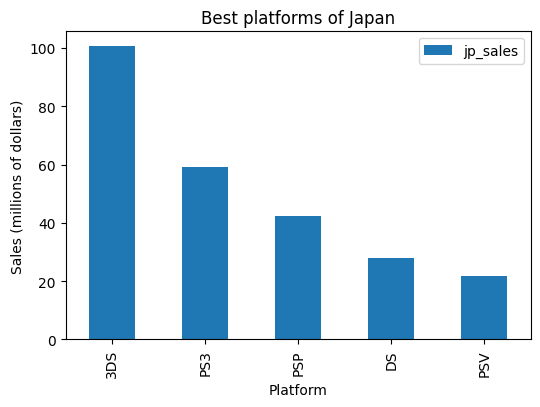

El promedio de ventas para las 5 mejoras plataformas de Japón es: 50.36400000000009 millones de dólares


In [204]:
# 4.2.1 Determinación de Japón
biggest_sales_jp = regional_sales_by_platform.sort_values(by='jp_sales', ascending=False)
print(biggest_sales_jp.head(5))
list_jp = biggest_sales_jp['platform'].head(5)
biggest_sales_jp = biggest_sales_jp[biggest_sales_jp['platform'].isin(list_jp)]
biggest_sales_jp = biggest_sales_jp.drop(columns=['na_sales', 'eu_sales'])
print(biggest_sales_jp)

biggest_sales_jp.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best platforms of Japan',
    x='platform',
    figsize=(6,4)
)
plt.show()
mean_best_jp_platforms = biggest_sales_jp['jp_sales'].mean()
print(f"El promedio de ventas para las 5 mejoras plataformas de Japón es: {mean_best_jp_platforms} millones de dólares")

          genre  na_sales  jp_sales  eu_sales
0        Action    290.64     72.20    233.63
1     Adventure     20.84     15.67     18.88
2      Fighting     39.05     13.90     20.33
3          Misc    123.80     24.29     66.09
4      Platform     54.90     15.81     38.30
5        Puzzle      9.10      3.40      6.58
6        Racing     46.11      6.68     54.75
7  Role-Playing    112.05    103.54     75.48
8       Shooter    237.47     14.04    171.45
9    Simulation     26.39     13.30     26.39


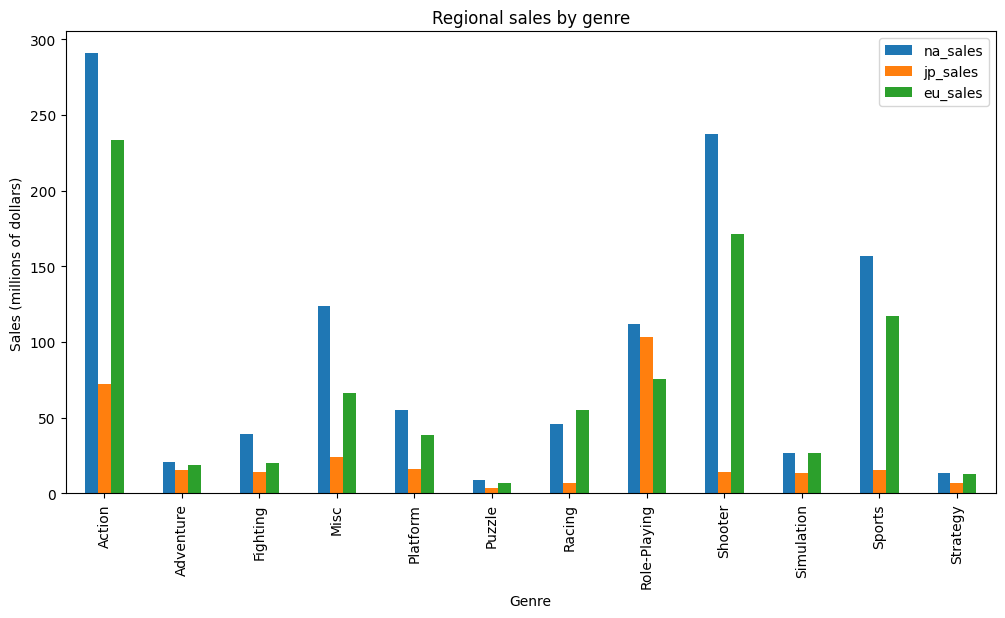

In [205]:
# 4.3 Determinación de los 5 géneros principales por región para explicar la diferencia.
# 4.3.1 Análisis inicial de todos los géneros por región para describir variaciones en cuotas de mercado de una región a otra
regional_sales_by_genre = games_recent.groupby('genre')[['na_sales', 'jp_sales', 'eu_sales']].sum().reset_index()
print(regional_sales_by_genre.head(10))
regional_sales_by_genre.plot(

    kind='bar',
    xlabel='Genre',
    ylabel='Sales (millions of dollars)',
    title='Regional sales by genre',
    x='genre',
    figsize=(12,6)

)
plt.show()

           genre  na_sales  jp_sales  eu_sales
0         Action    290.64     72.20    233.63
8        Shooter    237.47     14.04    171.45
10        Sports    156.81     15.51    116.84
3           Misc    123.80     24.29     66.09
7   Role-Playing    112.05    103.54     75.48
           genre  na_sales
0         Action    290.64
8        Shooter    237.47
10        Sports    156.81
3           Misc    123.80
7   Role-Playing    112.05


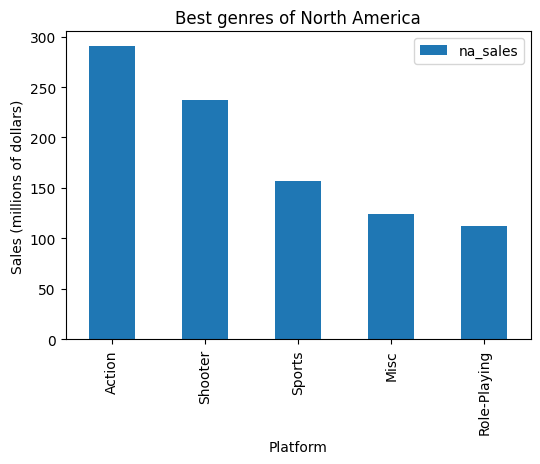

El promedio de ventas para los 5 mejores géneros de Norteamérica es: 184.15399999999968 millones de dólares


In [206]:
# 4.3.2 Determinación de Norteamérica
biggest_sales_na_genre = regional_sales_by_genre.sort_values(by='na_sales', ascending=False)
print(biggest_sales_na_genre.head(5))
list_na_genre = biggest_sales_na_genre['genre'].head(5)
biggest_sales_na_genre = biggest_sales_na_genre[biggest_sales_na_genre['genre'].isin(list_na_genre)]
biggest_sales_na_genre = biggest_sales_na_genre.drop(columns=['jp_sales', 'eu_sales'])
print(biggest_sales_na_genre)

biggest_sales_na_genre.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best genres of North America',
    x='genre',
    figsize=(6,4)
)
plt.show()
mean_best_na_genres = biggest_sales_na_genre['na_sales'].mean()
print(f"El promedio de ventas para los 5 mejores géneros de Norteamérica es: {mean_best_na_genres} millones de dólares")

           genre  na_sales  jp_sales  eu_sales
0         Action    290.64     72.20    233.63
8        Shooter    237.47     14.04    171.45
10        Sports    156.81     15.51    116.84
7   Role-Playing    112.05    103.54     75.48
3           Misc    123.80     24.29     66.09
           genre  eu_sales
0         Action    233.63
8        Shooter    171.45
10        Sports    116.84
7   Role-Playing     75.48
3           Misc     66.09


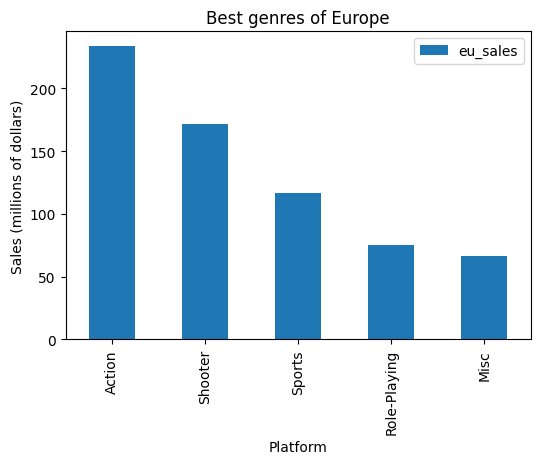

El promedio de ventas para los 5 mejores géneros de Europa es: 132.69800000000018 millones de dólares


In [207]:
# 4.3.2 Determinación de Europa
biggest_sales_eu_genre = regional_sales_by_genre.sort_values(by='eu_sales', ascending=False)
print(biggest_sales_eu_genre.head(5))
list_eu_genre = biggest_sales_eu_genre['genre'].head(5)
biggest_sales_eu_genre = biggest_sales_eu_genre[biggest_sales_eu_genre['genre'].isin(list_eu_genre)]
biggest_sales_eu_genre = biggest_sales_eu_genre.drop(columns=['jp_sales', 'na_sales'])
print(biggest_sales_eu_genre)

biggest_sales_eu_genre.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best genres of Europe',
    x='genre',
    figsize=(6,4)
)
plt.show()
mean_best_eu_genres = biggest_sales_eu_genre['eu_sales'].mean()
print(f"El promedio de ventas para los 5 mejores géneros de Europa es: {mean_best_eu_genres} millones de dólares")

          genre  na_sales  jp_sales  eu_sales
7  Role-Playing    112.05    103.54     75.48
0        Action    290.64     72.20    233.63
3          Misc    123.80     24.29     66.09
4      Platform     54.90     15.81     38.30
1     Adventure     20.84     15.67     18.88
          genre  jp_sales
7  Role-Playing    103.54
0        Action     72.20
3          Misc     24.29
4      Platform     15.81
1     Adventure     15.67


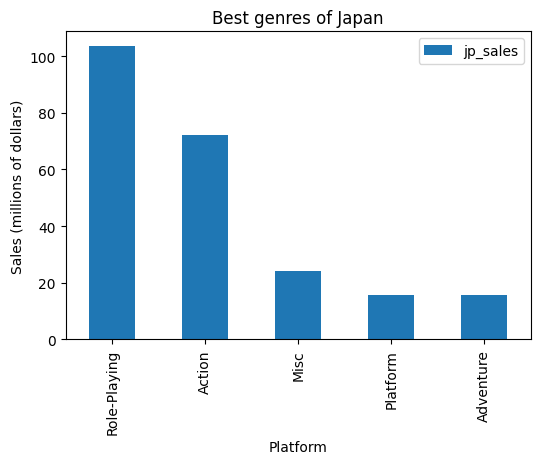

El promedio de ventas para los 5 mejores géneros de Japón es: 46.302000000000014 millones de dólares


In [208]:
# 4.3.2 Determinación de Japón
biggest_sales_jp_genre = regional_sales_by_genre.sort_values(by='jp_sales', ascending=False)
print(biggest_sales_jp_genre.head(5))
list_jp_genre = biggest_sales_jp_genre['genre'].head(5)
biggest_sales_jp_genre = biggest_sales_jp_genre[biggest_sales_jp_genre['genre'].isin(list_jp_genre)]
biggest_sales_jp_genre = biggest_sales_jp_genre.drop(columns=['eu_sales', 'na_sales'])
print(biggest_sales_jp_genre)

biggest_sales_jp_genre.plot(
    kind='bar',
    xlabel='Platform',
    ylabel='Sales (millions of dollars)',
    title='Best genres of Japan',
    x='genre',
    figsize=(6,4)
)
plt.show()
mean_best_jp_genres = biggest_sales_jp_genre['jp_sales'].mean()
print(f"El promedio de ventas para los 5 mejores géneros de Japón es: {mean_best_jp_genres} millones de dólares")

  rating  na_sales  jp_sales  eu_sales
0      E    271.15     47.87    197.34
1   E10+    159.38     13.22     99.28
2     EC      1.13      0.00      0.00
3      M    382.22     30.45    292.04
4     RP      0.00      0.00      0.03
5      T    160.81     42.11    113.08


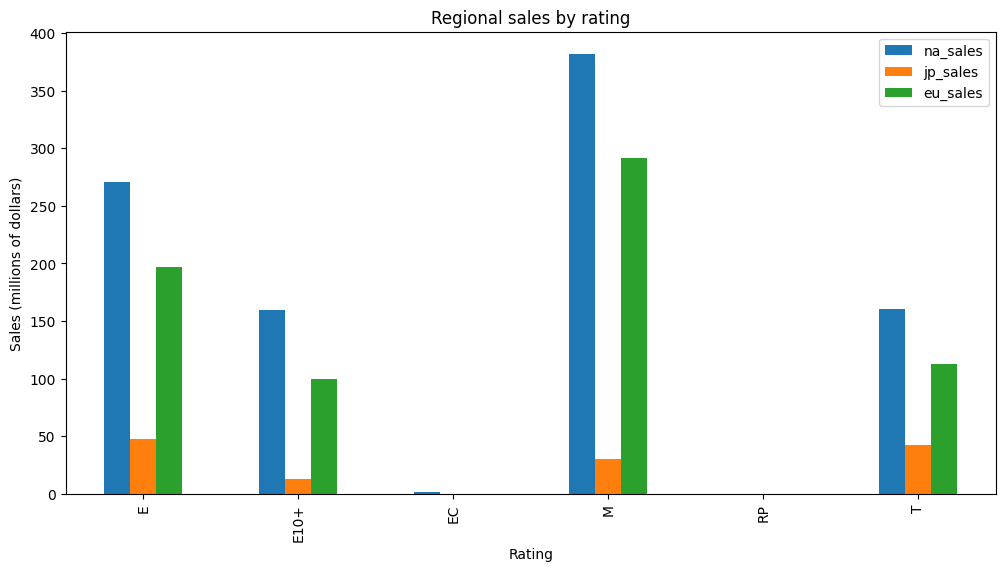

In [209]:
# 4.4 Análisis sobre el impacto de las clasificaciones ESRB en las ventas en regiones individuales
# 4.4.1 Análisis inicial de todas las clasificaciones por región para describir variaciones en cuotas de mercado de una región a otra
regional_sales_by_rating = games_recent.groupby('rating')[['na_sales', 'jp_sales', 'eu_sales']].sum().reset_index()
print(regional_sales_by_rating.head(10))
regional_sales_by_rating.plot(

    kind='bar',
    xlabel='Rating',
    ylabel='Sales (millions of dollars)',
    title='Regional sales by rating',
    x='rating',
    figsize=(12,6)

)
plt.show()

# CONCLUSIONES DEL PASO 4
1. De un primer vistazo a todas las plataformas con sus variaciones por región, es fácil ver que el mercado más importante para prácticamente todas es Norteamérica. Sin embargo, hay una nota muy importante: PS4 está mejor posicionado en este momento en Europa que en Norteamérica. En cambio, en la otra plataforma "viva" (XOne), Norteamérica vuelve a ser el mercado dominante. 
2. Percepción interesante: Japón prácticamente no usa PC como plataforma de videojuegos.
3. Destaca la diferencia entre las ventas de Norteamérica y Europa para X360: las ventas de Norteamérica rondan los 325 millones de dólares. La segunda región con más ventas, la Unión Europea, ronda los 150 millones de dólares.
4. Al analizar las mejores 5 plataformas por región, encontramos cosas interesantes. Sobre Norteamérica, la mejor plataforma en ventas es X360 con 325 millones de dólares, aproximadamente. La quinta mejor plataforma es XOne rondando los 100 millones de dólares. Es, en general, un mercado muy potente. Sin embargo, recordemos que X360 ha perdido vigencia. Por tanto, Los 100 millones de dólares de XOne son muy relevantes, porque seguramente este número crecerá con los años. Lo mismo con los 100 millones de PS4. 
5. En Europa, la mejor plataforma es PS3 con poco más de 200 millones de dólares. La quinta mejor es Wii con poco más de 50 millones de dólares. Lo más relevante: XOne no aparece en las 5 más importantes a pesar del criterio de periodo de vida, y PS4 sí. Esto significa que la penetración de PS4 es mayor en Europa que la de XOne Y, por tanto, esto construye un argumento de prioridad a favor de PS4 para lograr una participación en todos los mercados.
6. En Europa la PC es mucho más importante en años recientes que en Norteamérica. 
8. Japón varía: Es un mercado mucho más orientado a las consolas portátiles (3DS, PSP, DS, aunque también hay participación importante de PS3)
9. La consola con más ventas en Japón es 3DS con 100 millones de dólares aproximadamente. La quinta mejor es PSV (Playstation Vita) con aproximadamente 20 millones de dólares.
10. Los promedios de ventas por región en las 5 plataformas más importantes son los siguientes: Norteamérica, 491.8199999999977 millones de dólares; Europa, 278.28799999999757 millones de dólares; Japón, 134.36200000000022 millones de dólares.
11. Norteamérica y Europa comparten sus géneros top: Acción, shooter, deportes, misc y RPG. Cambia el orden sólo de los últimos 2: en Norteamérica está mejor posicionado el misc y en Europa, el RPG. 
13. En los 3 casos misc está presente. Esto quiere decir que los géneros no clasificados, en conjunto, ocupan un lugar importante ventas de las 3 regiones. Quizá valdría la pena desagregar esta categoría para tener más información.
14. Los promedios de ventas de los géneros más populares son: 184.15399 millones de dólares de Norteamérica; 132.698 millones de dólares de Europa y 46.302 millones de dólares de Japón.
15. En Japón los juegos de rol son ampliamente preferidos.
16. Salvo carreras, Norteamérica es la que más consume videojuegos de todos los géneros.
17. Las ventas no parecen ser sensibles al rating, en el sentido de que las proporciones de venta se mantienen más o menos constantes entre regiones.

# Paso 5: Prueba de hipótesis


H0: Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas. 
H1: Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC no son las mismas. 

Se define un alpha de 0.05. 

Regla de decisión: Rechazar H0 si el p-valor es menor al alpha. Se hace pruebas ttest con parámetro equal_var=False porque los grupos son diferentes entre sí y la información sobre ellos no permite considerar iguales las varianzas entre ambas poblaciones. Además, no se trata de muestras emparejadas.


In [210]:
# 5.1 PH: Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas
# Es una prueba de dos colas, porque la variación podría ser hacia arriba o hacia abajo.

user_score_xboxone = games_recent[games_recent["platform"] == "XOne"]["user_score"]
user_score_pc = games_recent[games_recent["platform"] == "PC"]["user_score"]

print(user_score_xboxone)
print()
print(user_score_pc)

99       NaN
165      7.9
179      5.4
242      6.4
270      6.2
        ... 
16630    8.2
16643    6.6
16645    NaN
16660    6.7
16672    NaN
Name: user_score, Length: 247, dtype: float64

192      4.0
218      8.2
313      8.1
458      3.9
480      5.9
        ... 
16658    NaN
16678    NaN
16692    7.6
16696    5.8
16702    7.2
Name: user_score, Length: 479, dtype: float64


In [211]:
stats.ttest_ind(user_score_xboxone, user_score_pc, equal_var=False, nan_policy='omit')

Ttest_indResult(statistic=0.024879518331077908, pvalue=0.9801634129117883)

Conclusión: Al ser el p-valor 0.9801634...) mayor que alpha (0.05), la conclusión correcta es mantener H0.

Eso significa que no hay evidencia estadísticamente significativa de que las calificaciones promedio de usuarios entre Xbox One y PC son diferentes.

H₀: Las calificaciones promedio de usuarios de Action y Sports son iguales.
H₁: Las calificaciones promedio de usuarios de Action y Sports son diferentes.

Se define un alpha de 0.05. 

Regla de decisión: Rechazar H0 si el p-valor es menor al alpha. Se hace pruebas ttest con parámetro equal_var=False porque los grupos son diferentes entre sí y la información sobre ellos no permite considerar iguales las varianzas entre ambas poblaciones. Además, no se trata de muestras emparejadas.


In [212]:
print(games['genre'].unique())

['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', ..., 'Action', 'Fighting', 'Adventure', 'Strategy', NaN]
Length: 13
Categories (12, object): ['Sports', 'Platform', 'Racing', 'Role-Playing', ..., 'Action', 'Fighting', 'Adventure', 'Strategy']


In [213]:


# 5.1 PH: Las calificaciones promedio de los usuarios para los géneros acción y deportes son las mismas
# Es una prueba de dos colas, porque la variación podría ser hacia arriba o hacia abajo.
# 
user_score_action = games_recent[games_recent["genre"] == "Action"]["user_score"]
user_score_sports = games_recent[games_recent["genre"] == "Sports"]["user_score"]

print(user_score_action)
print()
print(user_score_sports)

16       8.2
23       8.1
42       8.3
81       6.6
118      8.3
        ... 
16680    NaN
16691    NaN
16692    7.6
16699    NaN
16710    NaN
Name: user_score, Length: 1495, dtype: float64

77       4.3
94       5.0
119      NaN
122      NaN
126      4.3
        ... 
16534    NaN
16562    NaN
16638    NaN
16643    6.6
16688    NaN
Name: user_score, Length: 575, dtype: float64


In [214]:
stats.ttest_ind(user_score_action, user_score_sports, equal_var=False, nan_policy='omit')

Ttest_indResult(statistic=8.253196861110625, pvalue=1.4516152467843422e-15)

Como el p-valor (1.4516152467843422e-15) es menor que alpha (0.05), hay evidencia suficiente para rechazar H0.

Eso significa que, con los datos disponibles, se puede afirmar que las calificaciones promedio de usuarios entre los géneros de acción y deportes son diferentes.

# CONCLUSIONES DEL PASO 5
1. En ambos casos se hacen pruebas ttest con parámetro equal_var=False porque los grupos son diferentes entre sí y la información sobre ellos no permite considerar iguales las varianzas entre ambas poblaciones. Además, no se trata de muestras emparejadas.
2. En el primer paso, no hay evidencia suficiente para afirmar que  las calificaciones promedio de usuarios entre Xbox One y PC son diferentes.
3. En el segundo caso, en cambio, se puede afirmar que las calificaciones promedio de usuarios entre los géneros de acción y deportes son diferentes.

# PASO 6: CONCLUSIÓN GENERAL
1. La gráfica de vida parece descartar todas las opciones salvo PS4 Y XOne, que todavía estarán vivas para 2017. Esa estrategia, además, permitirá adentrarse también en el mercado europeo con relativos costos bajos de adecuación regional.
2. Debido a que en Japón para 2017 aún no hay una plataforma adecuada, quizá no sea un buen año para incursionar ahí. Sin embargo, 3DS sigue siendo medianamente relevante. 
3. El mercado más importante es Norteamérica. Hay que orientar la mayor cantidad de recursos hacia los géneros y las plataformas vivas con mejor desempeño ahí.
4. Action, Shooter y Sports son los géneros más importantes a desarrollar, tanto en Europa como en Norteamérica.
5. Si bien no es condición suficiente, tener buenas calificaciones sí parece ser condición necesaria para acceder a los rubros de mayores ventas. Por tanto, es buena idea acompañar el desarrollo de campañas de comunicación que fomenten calificaciones de 8 o equivalente para arriba.
6. En general la clasificación no parece jugar un rol muy importante. 